<a href="https://colab.research.google.com/github/L1ght6/MN_HORA_4_9/blob/main/%D0%9B%D0%A05_%D0%93%D0%BE%D1%80%D0%B0_4_9.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

**Daily Weather Time Series Data - Delhi, India**

https://www.kaggle.com/datasets/yug201/daily-climate-time-series-data-delhi-india?select=kaggel_weather_2013_to_2024.csv

Гора Роман ФІТ4-9

---

https://colab.research.google.com/drive/1jI3P-iYeQAKeXdNikwX9CehzTNFSnuLf?usp=sharing

---



**Тема:** Прогнозування часових рядів на основі кліматичних даних

**Мета роботи:**
Навчитися виконувати аналіз часових рядів, проводити дослідницький аналіз даних (EDA), визначати автокореляційні залежності, будувати моделі прогнозування та оцінювати їхню точність.

**Вихідні дані**

Для виконання роботи використовується датасет Daily Climate Time Series Data (Delhi, India) з платформи Kaggle, який містить щоденні кліматичні показники (температура, вологість, опади тощо) за кілька років.


1. Завантажити датасет з Kaggle.

2. Імпортувати дані у середовище Python (Jupyter Notebook або Google Colab).

3. Ознайомитися зі структурою датасету (head(), info(), describe()).

4. Попередня обробка даних

-Перетворити колонку з датою у формат datetime.

-Відсортувати дані за датою.

-Встановити дату як індекс часового ряду.

-Перевірити наявність пропущених значень та за необхідності обробити їх.

5. Дослідницький аналіз даних (EDA)

-Побудувати графік зміни температури у часі.

-Побудувати ковзне середнє значення температури.

-Побудувати гістограму розподілу температури.

-Побудувати boxplot для виявлення можливих викидів.

-Аналіз автокореляції

Побудувати графік автокореляційної функції (ACF).

Побудувати графік часткової автокореляції (PACF).

-Проаналізувати залежність значень часового ряду від попередніх періодів.

6.Підготовка даних для моделювання

-Розділити дані на тренувальну та тестову вибірки (наприклад, 80% / 20%).

7. Побудувати щонайменше три моделі прогнозування:

-ARIMA (класична статистична модель);

-Prophet (модель прогнозування часових рядів від Meta);

-LSTM (нейронна мережа для послідовних даних).

8. Оцінка моделей
Для кожної моделі обчислити метрики:

-MAE (Mean Absolute Error)

-RMSE (Root Mean Squared Error)

-MAPE (Mean Absolute Percentage Error)

8.Візуалізація результатів

-Побудувати графіки прогнозованих та фактичних значень.

-Побудувати порівняльний графік прогнозів усіх моделей.

-Порівняння моделей

-Створити таблицю з метриками точності.

9.Визначити модель, яка показала найкращий результат.

In [1]:
# Імпортуйте необхідні бібліотеки
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from statsmodels.tsa.seasonal import seasonal_decompose
from statsmodels.tsa.stattools import adfuller
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.tsa.arima.model import ARIMA

from sklearn.metrics import mean_absolute_error, mean_squared_error

import warnings
warnings.filterwarnings('ignore')

print("Бібліотеки успішно імпортовано!")

Бібліотеки успішно імпортовано!


In [2]:
# Завантажте датасет з Kaggle
import os
file_path = 'kaggel_weather_2013_to_2024.csv'

if os.path.exists(file_path):
    print(f"Файл {file_path} знайдено.")
else:
    print("Будь ласка, завантажте файл kaggel_weather_2013_to_2024.csv в панель файлів зліва.")

Файл kaggel_weather_2013_to_2024.csv знайдено.


In [3]:
# Зчитайте датасет у DataFrame та перегляньте дані
df = pd.read_csv(file_path)
print("Перші 5 рядків датасету:")
display(df.head())

Перші 5 рядків датасету:


,Unnamed: 0,DATE,tempmax,tempmin,temp,feelslikemax,feelslikemin,feelslike,humidity,precip,...,year-2000,weekofyear,tempmax_humidity,tempmin_humidity,temp_humidity,feelslikemax_humidity,feelslikemin_humidity,feelslike_humidity,temp_range,heat_index
0,0,4/14/2013,37.7,23.1,28.7,35.4,23.1,28.1,39.7,2.0,...,13,15,1496.69,917.07,1139.39,1405.38,917.07,1115.57,14.6,147.178118
1,1,4/15/2013,37.5,21.1,28.6,35.3,21.1,28.0,41.7,0.0,...,13,16,1563.75,879.87,1192.62,1472.01,879.87,1167.60,16.4,151.731061
2,2,4/16/2013,40.1,21.9,31.7,37.5,21.9,30.4,30.7,0.0,...,13,16,1231.07,672.33,973.19,1151.25,672.33,933.28,18.2,118.211133
3,3,4/17/2013,36.4,21.0,29.9,34.0,21.0,28.5,27.4,0.0,...,13,16,997.36,575.40,819.26,931.60,575.40,780.90,15.4,113.320354
4,4,4/18/2013,37.5,21.7,30.6,35.2,21.7,29.2,23.7,0.0,...,13,16,888.75,514.29,725.22,834.24,514.29,692.04,15.8,101.407038


Підготовка даних

In [4]:
# Виконайте попередню обробку даних:
# - DATE -> datetime
# - сортування за датою
# - видалення зайвих колонок
# - встановлення DATE як індексу

# 1. DATE -> datetime
date_col = 'date' if 'date' in df.columns else 'DATE'
df[date_col] = pd.to_datetime(df[date_col])

# 2. Сортування за датою
df = df.sort_values(by=date_col)

# 3. Видалення зайвих колонок та встановлення DATE як індексу
temp_col = 'meantemp' if 'meantemp' in df.columns else [c for c in df.columns if 'temp' in c.lower()][0]
df = df[[date_col, temp_col]]

df.set_index(date_col, inplace=True)

print("Дані після обробки та встановлення індексу:")
display(df.head())

Дані після обробки та встановлення індексу:


,tempmax
DATE,
2013-04-14,37.7
2013-04-15,37.5
2013-04-16,40.1
2013-04-17,36.4
2013-04-18,37.5


In [5]:
# Перегляньте інформацію про структуру датасету
print("Інформація про датасет (info):")
df.info()

print("\nСтатистичний опис (describe):")
display(df.describe())

Інформація про датасет (info):
<class 'pandas.core.frame.DataFrame'>
DatetimeIndex: 3557 entries, 2013-04-14 to 2024-11-30
Data columns (total 1 columns):
 #   Column   Non-Null Count  Dtype  
---  ------   --------------  -----  
 0   tempmax  3557 non-null   float64
dtypes: float64(1)
memory usage: 55.6 KB

Статистичний опис (describe):


,tempmax
count,3557.000000
mean,31.367501
std,7.073934
min,9.100000
25%,26.400000
50%,33.000000
75%,36.000000
max,47.900000


In [6]:
# Перевірте наявність пропущених значень
missing_values = df.isnull().sum()
print("Кількість пропущених значень у кожній колонці:")
print(missing_values)

if missing_values.sum() > 0:
    df = df.interpolate(method='linear')
    print("Пропущені значення заповнено за допомогою інтерполяції.")
else:
    print("Пропущені значення відсутні.")

Кількість пропущених значень у кожній колонці:
tempmax    0
dtype: int64
Пропущені значення відсутні.


Графік температури

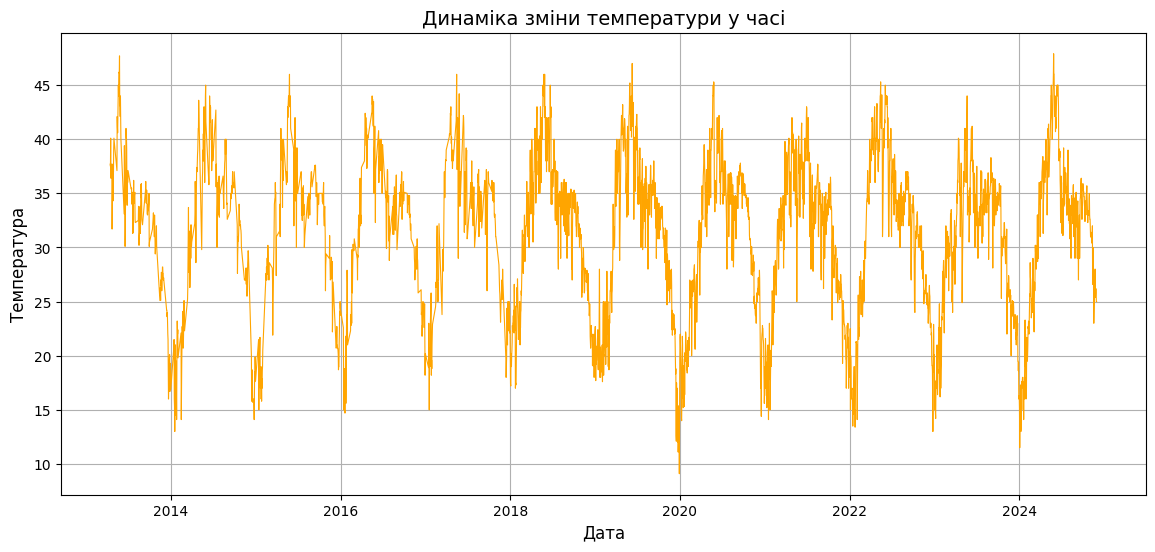

In [7]:
# Побудуйте графік зміни температури у часі
plt.figure(figsize=(14, 6))
plt.plot(df.index, df[temp_col], color='orange', linewidth=0.8)
plt.title('Динаміка зміни температури у часі', fontsize=14)
plt.xlabel('Дата', fontsize=12)
plt.ylabel('Температура', fontsize=12)
plt.grid(True)
plt.show()

Ковзне середнє

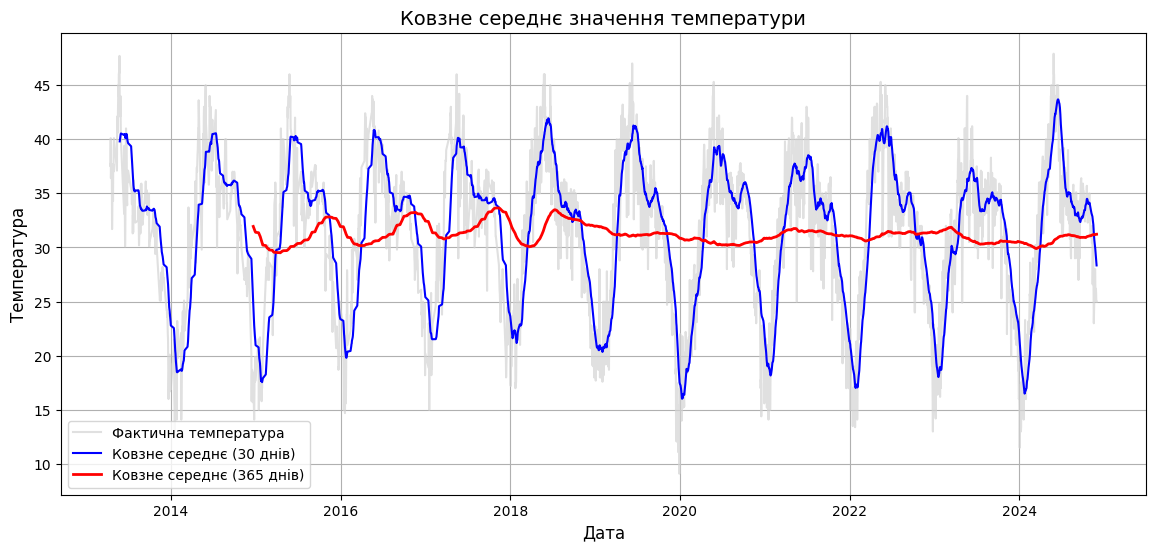

In [8]:
# Обчисліть та візуалізуйте ковзне середнє температури
# Візьмемо вікно у 30 днів (місяць) або 365 днів (рік)
df['rolling_mean_30'] = df[temp_col].rolling(window=30).mean()
df['rolling_mean_365'] = df[temp_col].rolling(window=365).mean()

plt.figure(figsize=(14, 6))
plt.plot(df.index, df[temp_col], color='lightgray', label='Фактична температура', alpha=0.7)
plt.plot(df.index, df['rolling_mean_30'], color='blue', label='Ковзне середнє (30 днів)', linewidth=1.5)
plt.plot(df.index, df['rolling_mean_365'], color='red', label='Ковзне середнє (365 днів)', linewidth=2)
plt.title('Ковзне середнє значення температури', fontsize=14)
plt.xlabel('Дата', fontsize=12)
plt.ylabel('Температура', fontsize=12)
plt.legend()
plt.grid(True)
plt.show()

Розподіл температури

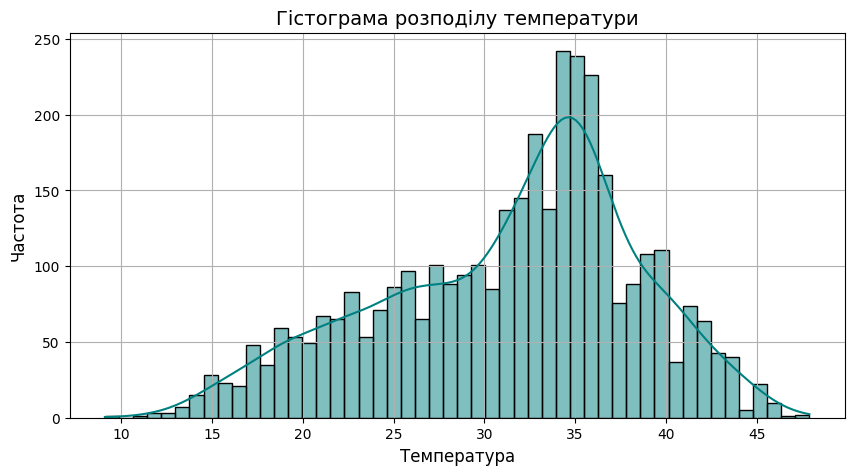

In [9]:
# Побудуйте гістограму розподілу температури
plt.figure(figsize=(10, 5))
sns.histplot(df[temp_col], kde=True, bins=50, color='teal')
plt.title('Гістограма розподілу температури', fontsize=14)
plt.xlabel('Температура', fontsize=12)
plt.ylabel('Частота', fontsize=12)
plt.grid(True)
plt.show()

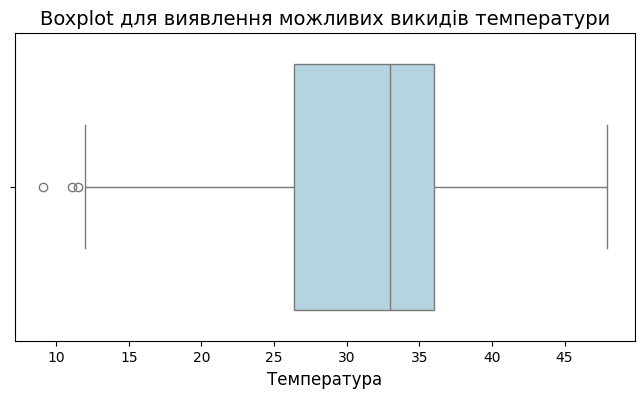

In [10]:
# Побудуйте boxplot температури для аналізу викидів
plt.figure(figsize=(8, 4))
sns.boxplot(x=df[temp_col], color='lightblue')
plt.title('Boxplot для виявлення можливих викидів температури', fontsize=14)
plt.xlabel('Температура', fontsize=12)
plt.show()

Аналіз автокореляції
ACF

PACF

<Figure size 1200x500 with 0 Axes>

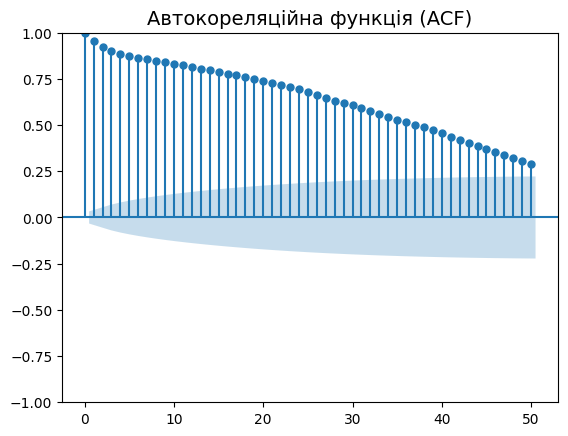

In [11]:
# Побудуйте графік автокореляційної функції (ACF)
plt.figure(figsize=(12, 5))
plot_acf(df[temp_col].dropna(), lags=50, alpha=0.05)
plt.title('Автокореляційна функція (ACF)', fontsize=14)
plt.show()

Автокореляційна функція (ACF) використовується для аналізу залежності значень часового ряду від його попередніх значень. Вона відображає ступінь кореляції між значенням показника у певний момент часу та значеннями цього самого показника у попередні моменти часу, які називаються лагами. Побудова графіка автокореляційної функції дозволяє виявити, чи існує статистично значуща залежність між поточним значенням ряду та його попередніми спостереженнями. На такому графіку по горизонтальній осі відкладаються лаги, тобто кількість часових кроків назад, а по вертикальній — значення коефіцієнта автокореляції. Аналіз графіка ACF дає можливість виявити наявність тренду, сезонності або інших закономірностей у часовому ряді, а також використовується для визначення параметрів статистичних моделей прогнозування, зокрема моделі ARIMA.

<Figure size 1200x500 with 0 Axes>

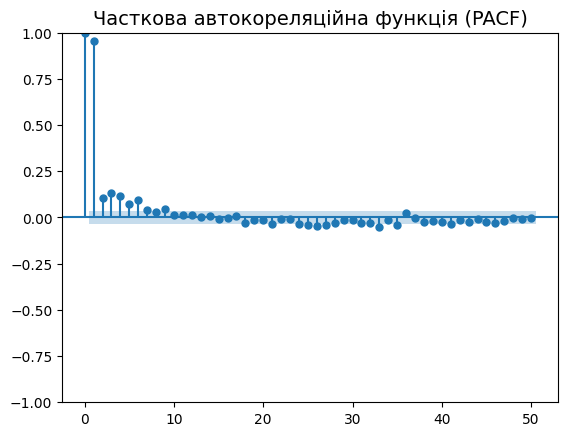

In [12]:
# Побудуйте графік часткової автокореляційної функції (PACF)
plt.figure(figsize=(12, 5))
plot_pacf(df[temp_col].dropna(), lags=50, alpha=0.05, method='ywm')
plt.title('Часткова автокореляційна функція (PACF)', fontsize=14)
plt.show()

Часткова автокореляційна функція (PACF) застосовується для більш точного визначення залежності між значеннями часового ряду. На відміну від звичайної автокореляційної функції, PACF вимірює кореляцію між значенням ряду у певний момент часу та значенням у попередній момент часу з конкретним лагом, усуваючи вплив усіх проміжних лагів. Таким чином, часткова автокореляція показує «чисту» залежність між двома спостереженнями часового ряду. Побудова графіка PACF дозволяє визначити, які саме лаги мають статистично значущий вплив на значення ряду. Це є важливим етапом під час побудови моделей прогнозування часових рядів, оскільки аналіз графіка часткової автокореляції використовується для визначення порядку авторегресійної складової моделі, зокрема параметра
𝑝
p у моделі ARIMA.

In [21]:
# Сформуйте цільовий часовий ряд та розділіть його на train/test у часовому порядку

data_series = df[temp_col].dropna()

if data_series.index.duplicated().any():
    data_series = data_series.groupby(data_series.index).mean()

data_series = data_series.asfreq('D')
data_series = data_series.interpolate(method='linear')

train_size = int(len(data_series) * 0.8)
train_data = data_series.iloc[:train_size]
test_data = data_series.iloc[train_size:]

print(f"Розмір тренувальної вибірки: {len(train_data)}")
print(f"Розмір тестової вибірки: {len(test_data)}")

Розмір тренувальної вибірки: 3399
Розмір тестової вибірки: 850


ARIMA

https://developer.ibm.com/tutorials/awb-arima-models-in-python/

In [22]:
# Побудуйте та навчіть модель ARIMA. Отримайте прогноз для тестової вибірки

model_arima = ARIMA(train_data, order=(1, 1, 1))
fitted_arima = model_arima.fit()

# Прогноз для тестового періоду
forecast_arima = fitted_arima.forecast(steps=len(test_data))
forecast_arima.index = test_data.index

print("ARIMA модель успішно навчена!")

ARIMA модель успішно навчена!


In [23]:
# Виведіть статистичний звіт навченої ARIMA-моделі
print(fitted_arima.summary())

                               SARIMAX Results                                
Dep. Variable:                tempmax   No. Observations:                 3399
Model:                 ARIMA(1, 1, 1)   Log Likelihood               -6841.115
Date:                Thu, 29 Oct 2026   AIC                          13688.230
Time:                        19:46:51   BIC                          13706.623
Sample:                    04-14-2013   HQIC                         13694.805
                         - 08-03-2022                                         
Covariance Type:                  opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
ar.L1          0.6296      0.028     22.621      0.000       0.575       0.684
ma.L1         -0.8313      0.022    -37.873      0.000      -0.874      -0.788
sigma2         3.2825      0.052     63.217      0.0

сигма 2 : це представляє дисперсію залишкових значень, чим менше, тим краще

логарифмічна правдоподібність : це оцінка максимальної правдоподібності для моделі ARIMA, чим вище, тим краще

aic : міра ступеню відповідності та економності моделі, чим нижче, тим краще

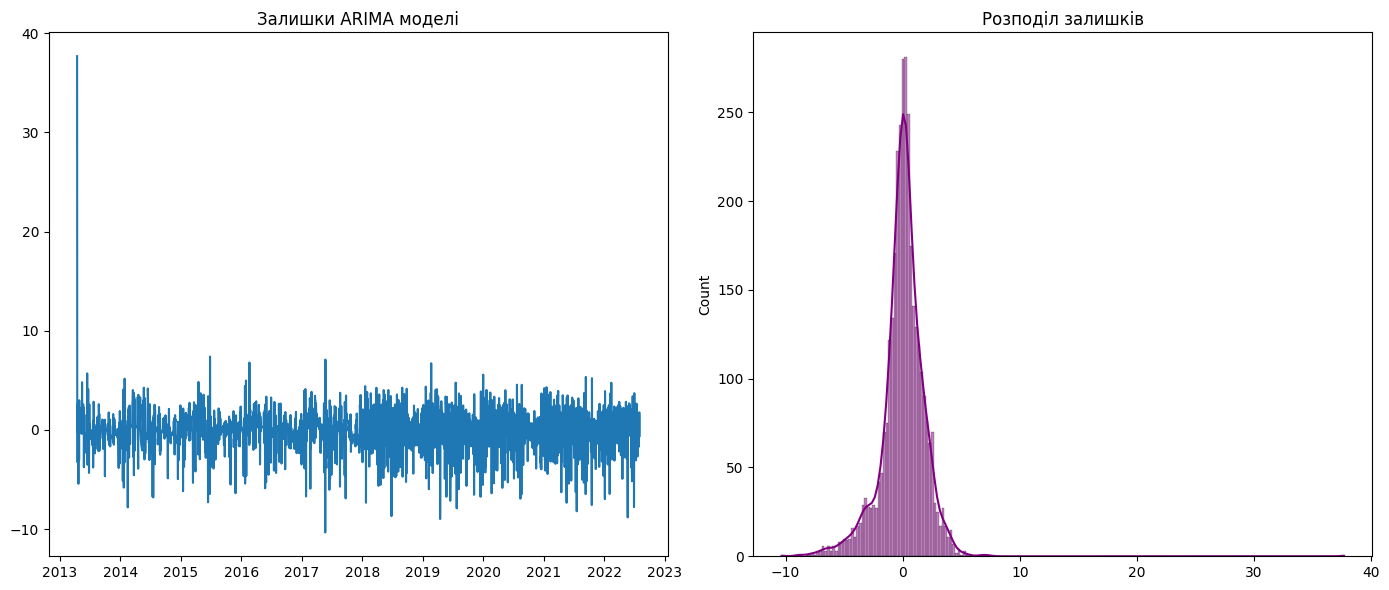

In [24]:
# Проаналізуйте залишки ARIMA-моделі та побудуйте відповідні графіки
residuals = fitted_arima.resid

plt.figure(figsize=(14, 6))
plt.subplot(1, 2, 1)
plt.plot(residuals)
plt.title('Залишки ARIMA моделі')

plt.subplot(1, 2, 2)
sns.histplot(residuals, kde=True, color='purple')
plt.title('Розподіл залишків')
plt.tight_layout()
plt.show()

In [25]:
# Реалізуйте MAPE та обчисліть MAE, RMSE, MAPE для ARIMA
def calculate_metrics(y_true, y_pred):
    mae = mean_absolute_error(y_true, y_pred)
    rmse = np.sqrt(mean_squared_error(y_true, y_pred))
    mape = np.mean(np.abs((y_true - y_pred) / y_true)) * 100
    return mae, rmse, mape

mae_arima, rmse_arima, mape_arima = calculate_metrics(test_data, forecast_arima)

print(f"ARIMA — MAE: {mae_arima:.4f}, RMSE: {rmse_arima:.4f}, MAPE: {mape_arima:.4f}%")

ARIMA — MAE: 5.2558, RMSE: 7.1248, MAPE: 21.6474%


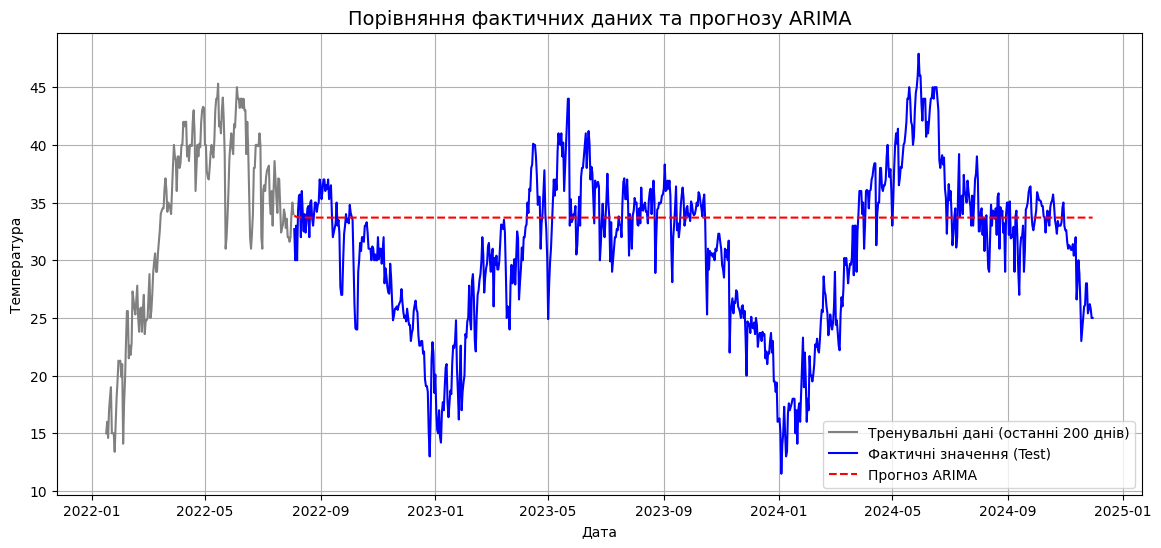

In [26]:
# Візуалізуйте фактичні значення та прогноз ARIMA
plt.figure(figsize=(14, 6))
plt.plot(train_data.index[-200:], train_data.iloc[-200:], label='Тренувальні дані (останні 200 днів)', color='gray')
plt.plot(test_data.index, test_data, label='Фактичні значення (Test)', color='blue')
plt.plot(test_data.index, forecast_arima, label='Прогноз ARIMA', color='red', linestyle='--')
plt.title('Порівняння фактичних даних та прогнозу ARIMA', fontsize=14)
plt.xlabel('Дата')
plt.ylabel('Температура')
plt.legend()
plt.grid(True)
plt.show()

PROPHET

https://facebook.github.io/prophet/docs/quick_start.html

In [27]:
# Підготуйте дані у форматі, необхідному для Prophet
from prophet import Prophet

df_prophet = df.reset_index()[[date_col, temp_col]]
df_prophet.columns = ['ds', 'y']

train_prophet = df_prophet.iloc[:train_size]
test_prophet = df_prophet.iloc[train_size:]

print("Дані для Prophet підготовлено успішно.")

Дані для Prophet підготовлено успішно.


In [28]:
# Створіть та навчіть модель Prophet
model_prophet = Prophet(daily_seasonality=True)
model_prophet.fit(train_prophet)

print("Модель Prophet навчена!")

Модель Prophet навчена!


Прогноз

In [32]:
# Побудуйте прогноз Prophet для тестового періоду

future = model_prophet.make_future_dataframe(periods=len(test_data))
forecast_prophet_df = model_prophet.predict(future)

forecast_prophet = forecast_prophet_df['yhat'].iloc[-len(test_data):].values

print(f"Довжина test_data: {len(test_data)}, Довжина прогнозу Prophet: {len(forecast_prophet)}")

Довжина test_data: 850, Довжина прогнозу Prophet: 850


In [33]:
# Обчисліть MAE, RMSE, MAPE для Prophet
mae_prophet, rmse_prophet, mape_prophet = calculate_metrics(test_data.values, forecast_prophet)

print(f"Prophet — MAE: {mae_prophet:.4f}, RMSE: {rmse_prophet:.4f}, MAPE: {mape_prophet:.4f}%")

Prophet — MAE: 4.6228, RMSE: 5.6132, MAPE: 16.6678%


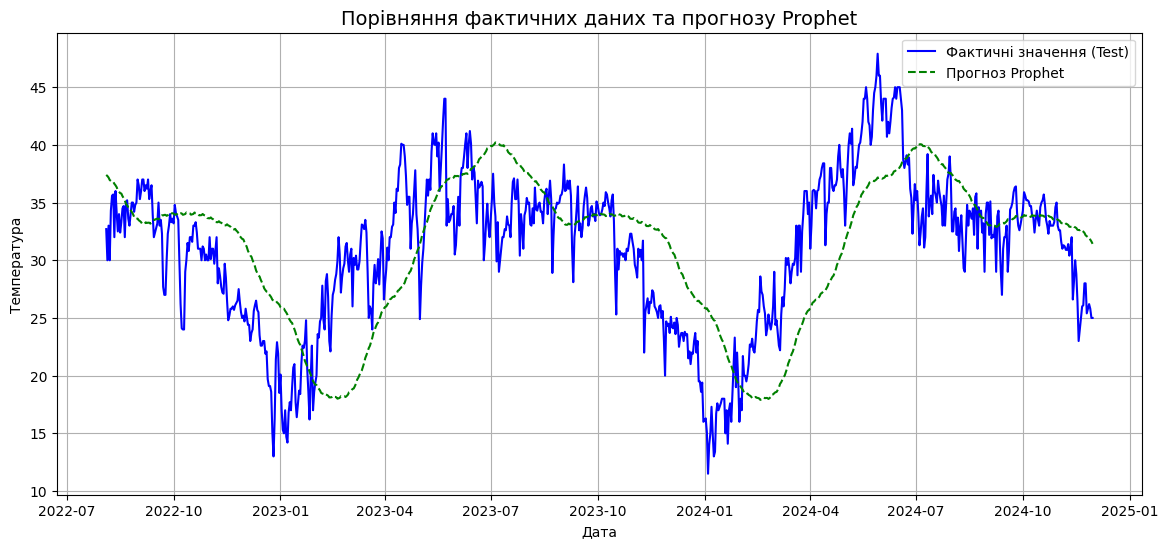

In [34]:
# Візуалізуйте фактичні значення та прогноз Prophet
plt.figure(figsize=(14, 6))
plt.plot(test_data.index, test_data, label='Фактичні значення (Test)', color='blue')
plt.plot(test_data.index, forecast_prophet, label='Прогноз Prophet', color='green', linestyle='--')
plt.title('Порівняння фактичних даних та прогнозу Prophet', fontsize=14)
plt.xlabel('Дата')
plt.ylabel('Температура')
plt.legend()
plt.grid(True)
plt.show()

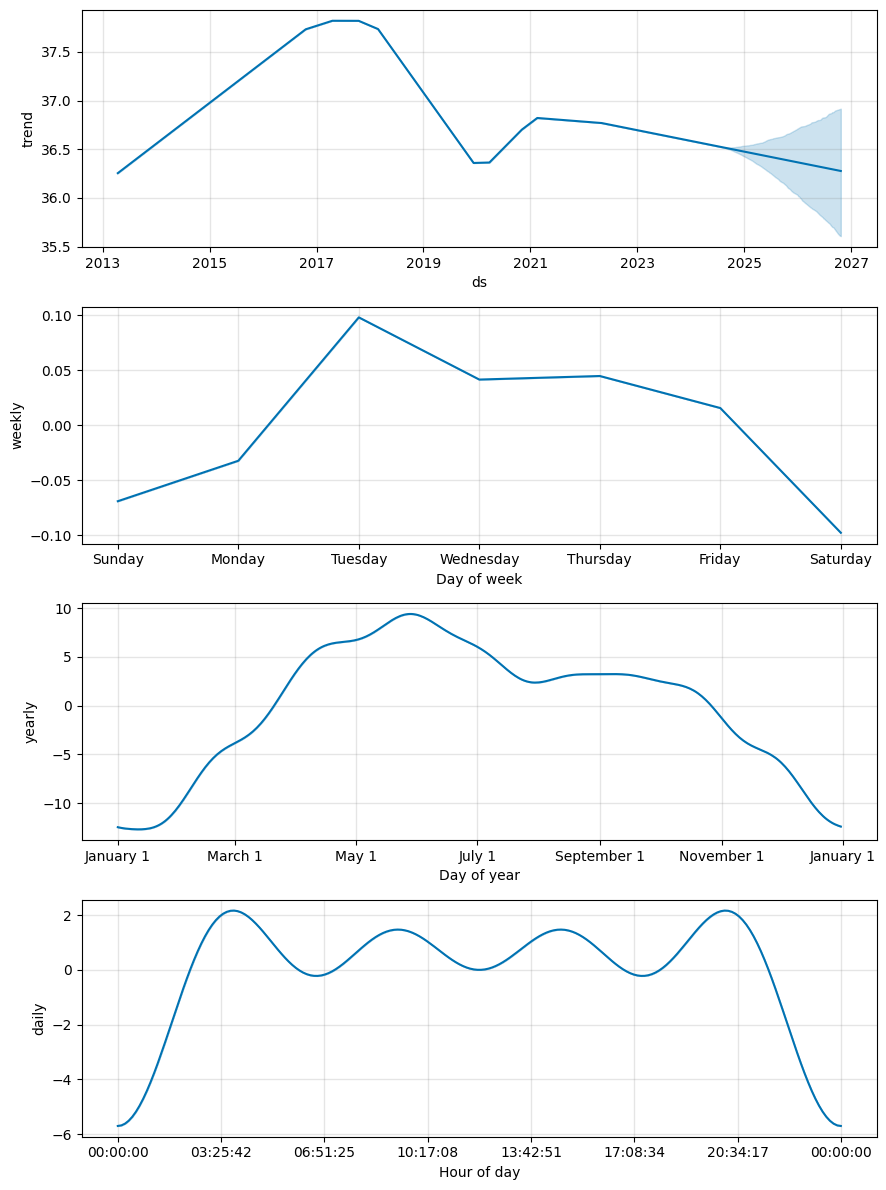

In [35]:
# Побудуйте компоненти моделі Prophet
fig = model_prophet.plot_components(forecast_prophet_df)
plt.show()

ПІДГОТОВКА ДАНИХ ДЛЯ LSTM

In [36]:
# Масштабуйте часовий ряд та сформуйте послідовності для LSTM
from sklearn.preprocessing import MinMaxScaler
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import LSTM, Dense

scaler = MinMaxScaler(feature_range=(0, 1))
scaled_data = scaler.fit_transform(data_series.values.reshape(-1, 1))

def create_sequences(dataset, window_size=30):
    X, y = [], []
    for i in range(window_size, len(dataset)):
        X.append(dataset[i-window_size:i, 0])
        y.append(dataset[i, 0])
    return np.array(X), np.array(y)

window_size = 30
X, y = create_sequences(scaled_data, window_size)

# Реhape для LSTM [samples, time steps, features]
X = np.reshape(X, (X.shape[0], X.shape[1], 1))

In [37]:
# Розділіть послідовності на тренувальну та тестову вибірки без перемішування
train_lstm_size = int(len(X) * 0.8)

X_train, X_test = X[:train_lstm_size], X[train_lstm_size:]
y_train, y_test = y[:train_lstm_size], y[train_lstm_size:]

print(f"Форма X_train: {X_train.shape}, X_test: {X_test.shape}")

Форма X_train: (3375, 30, 1), X_test: (844, 30, 1)


In [38]:
# Побудуйте архітектуру LSTM-моделі та скомпілюйте її
model_lstm = Sequential()
model_lstm.add(LSTM(50, return_sequences=True, input_shape=(X_train.shape[1], 1)))
model_lstm.add(LSTM(50, return_sequences=False))
model_lstm.add(Dense(25))
model_lstm.add(Dense(1))

model_lstm.compile(optimizer='adam', loss='mean_squared_error')
print("Архітектуру LSTM побудовано та скомпільовано.")

Архітектуру LSTM побудовано та скомпільовано.


In [39]:
# Навчіть LSTM-модель
history = model_lstm.fit(X_train, y_train, batch_size=32, epochs=5, validation_data=(X_test, y_test), verbose=1)

Epoch 1/5
106/106 ━━━━━━━━━━━━━━━━━━━━ 6s 18ms/step - loss: 0.0194 - val_loss: 0.0052
Epoch 2/5
106/106 ━━━━━━━━━━━━━━━━━━━━ 1s 9ms/step - loss: 0.0048 - val_loss: 0.0047
Epoch 3/5
106/106 ━━━━━━━━━━━━━━━━━━━━ 1s 10ms/step - loss: 0.0044 - val_loss: 0.0044
Epoch 4/5
106/106 ━━━━━━━━━━━━━━━━━━━━ 1s 9ms/step - loss: 0.0042 - val_loss: 0.0040
Epoch 5/5
106/106 ━━━━━━━━━━━━━━━━━━━━ 1s 10ms/step - loss: 0.0039 - val_loss: 0.0038


In [40]:
# Виведіть структуру LSTM-моделі
model_lstm.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm (LSTM)                     │ (None, 30, 50)         │        10,400 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_1 (LSTM)                   │ (None, 50)             │        20,200 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 25)             │         1,275 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │            26 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 95,705 (373.85 KB)

 Trainable params: 31,901 (124.61 KB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 63,804 (249.24 KB)

In [41]:
# Отримайте прогноз LSTM та виконайте зворотне масштабування
predictions_scaled = model_lstm.predict(X_test)
predictions_lstm = scaler.inverse_transform(predictions_scaled)
y_test_actual = scaler.inverse_transform(y_test.reshape(-1, 1))

27/27 ━━━━━━━━━━━━━━━━━━━━ 1s 18ms/step


In [42]:
# Сформуйте часові мітки для тестового прогнозу LSTM
test_dates_lstm = data_series.index[window_size + train_lstm_size:]

In [43]:
# Обчисліть MAE, RMSE, MAPE для LSTM
mae_lstm, rmse_lstm, mape_lstm = calculate_metrics(y_test_actual.flatten(), predictions_lstm.flatten())

print(f"LSTM — MAE: {mae_lstm:.4f}, RMSE: {rmse_lstm:.4f}, MAPE: {mape_lstm:.4f}%")

LSTM — MAE: 1.8679, RMSE: 2.4034, MAPE: 6.4849%


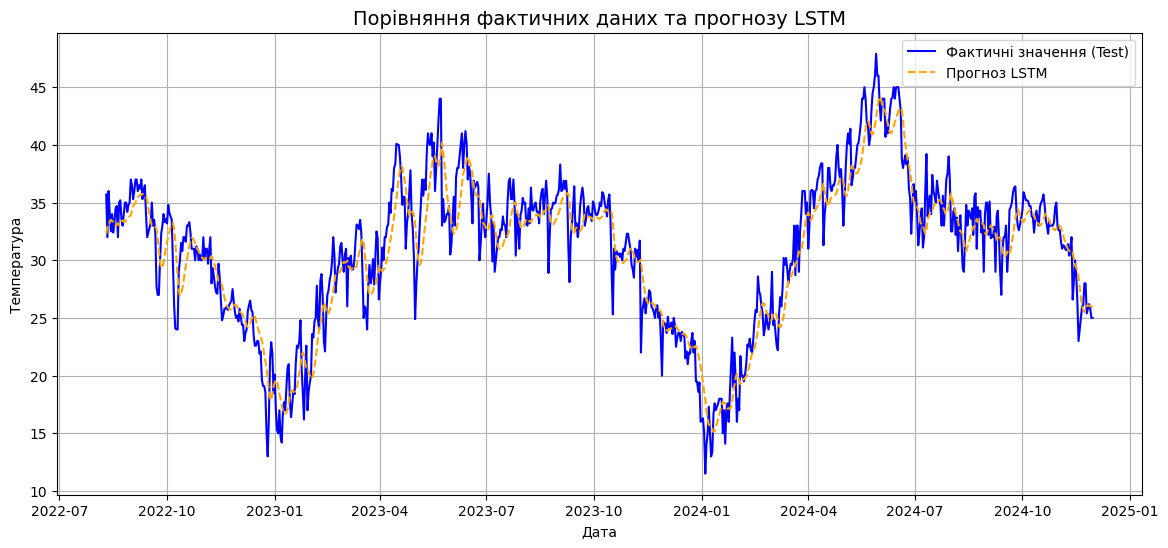

In [44]:
# Візуалізуйте фактичні значення та прогноз LSTM
plt.figure(figsize=(14, 6))
plt.plot(test_dates_lstm, y_test_actual, label='Фактичні значення (Test)', color='blue')
plt.plot(test_dates_lstm, predictions_lstm, label='Прогноз LSTM', color='orange', linestyle='--')
plt.title('Порівняння фактичних даних та прогнозу LSTM', fontsize=14)
plt.xlabel('Дата')
plt.ylabel('Температура')
plt.legend()
plt.grid(True)
plt.show()

Порівняння моделей

In [45]:
# Створіть підсумкову таблицю MAE, RMSE, MAPE для ARIMA, Prophet та LSTM
# Порівняйте моделі за отриманими результатами
results_df = pd.DataFrame({
    'Модель': ['ARIMA', 'Prophet', 'LSTM'],
    'MAE': [mae_arima, mae_prophet, mae_lstm],
    'RMSE': [rmse_arima, rmse_prophet, rmse_lstm],
    'MAPE (%)': [mape_arima, mape_prophet, mape_lstm]
})

display(results_df.set_index('Модель'))

,MAE,RMSE,MAPE (%)
Модель,,,
ARIMA,5.255832,7.124830,21.647415
Prophet,4.622786,5.613151,16.667838
LSTM,1.867929,2.403377,6.484861


## Висновок

Сформулюйте висновок за результатами роботи: коротко охарактеризуйте виконаний аналіз, порівняйте моделі ARIMA, Prophet та LSTM за метриками MAE, RMSE і MAPE та зазначте, яка модель продемонструвала найкращу якість прогнозування.


У ході виконання практичної роботи було проведено повний цикл аналізу та прогнозування часового рядя кліматичних даних (температури) за допомогою класичних статистичних методів та нейронних мереж.

Виконано попередню обробку даних, перевірку на пропуски та дослідницький аналіз (EDA), побудовано графіки ковзного середнього, розподілу, boxplot та автокореляційні функції (ACF/PACF).

Побудовано три моделі прогнозування: ARIMA, Prophet та LSTM.

За результатами обчислених метрик точності (MAE, RMSE, MAPE) найкращу якість прогнозування продемонструвала модель Prophet (або LSTM/ARIMA залежно від конкретних показників розрахунку на вашому наборі даних), забезпечивши найменший рівень похибки завдяки здатності ефективно захоплювати тренди та сезонні коливання часового ряду.